# Statistical testing of detectors (Friedman & Nemenyi tests)

In [1]:
# Import required libraries
import sys
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
from scipy import stats
import seaborn as sns

# Add parent directory to path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.statistical_tests import evaluate_detectors_statistically

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Input data

In [2]:
data_dir = "../data"
processed_dir = Path(data_dir) / "processed"
detectors_results_path = processed_dir / "multi_series_detector_comparison_results.csv"

## 1. Data preparation

In [3]:
df_raw = pd.read_csv(detectors_results_path)

print(f"Original shape: {df_raw.shape}")
print("Unique datasets:", df_raw["dataset"].unique())
print("Unique methods:", df_raw["method"].unique())
print("Drift types present:", df_raw["drift_type"].unique())

Original shape: (679, 15)
Unique datasets: <ArrowStringArray>
['Alibaba', 'UCI_Electricity', 'TCPD']
Length: 3, dtype: str
Unique methods: <ArrowStringArray>
[                'ks',                'psi',        'wasserstein',
              'adwin',       'page_hinkley',              'kswin',
 'residual_conformal']
Length: 7, dtype: str
Drift types present: <ArrowStringArray>
['none', 'abrupt', 'gradual', 'seasonal_amplitude',
 'real_consensus_annotation']
Length: 5, dtype: str


### Level 1. FAR per 1000

In [4]:
# Filter out level 1 drift scenarios to evaluate detection performance (FAR per 1000) on actual drift instances
df_drift = df_raw[(df_raw["level"] == 1)].copy()

In [5]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "series_id", "level"]

df_pivot_far_per_1000 = (
    df_drift.groupby(benchmark_id_cols + ["method"])["far_per_1000"]
    .mean()
    .unstack(level="method")
)

In [6]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_far_per_1000 = df_pivot_far_per_1000.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_far_per_1000.shape}")
df_pivot_far_per_1000


Pivoted Data Shape for Statistical Tests: (10, 7)


method                                             adwin         ks     kswin  \
dataset         series_id                level                                  
Alibaba         alibaba_mem_util_percent 1      6.241641  20.508248  9.362461   
                alibaba_net_in           1      2.674989  32.099866  8.916630   
TCPD            iceland_tourism          1      0.000000   0.000000  5.025126   
                jfk_passengers           1      0.000000   0.000000  0.000000   
                us_population            1      0.000000   0.000000  1.225490   
UCI_Electricity MT_209                   1      0.228311   2.397260  2.739726   
                MT_241                   1      0.456621   5.365297  3.424658   
                MT_242                   1      0.342466   3.196347  2.397260   
                MT_265                   1      0.228311   0.799087  1.598174   
                MT_291                   1      0.228311   3.652968  3.310502   

method                                          page_hinkley        psi  \
dataset         series_id                level                            
Alibaba         alibaba_mem_util_percent 1         14.712439  36.558181   
                alibaba_net_in           1          0.891663  36.112350   
TCPD            iceland_tourism          1         30.150754   0.000000   
                jfk_passengers           1         32.051282  19.230769   
                us_population            1         33.088235  28.186275   
UCI_Electricity MT_209                   1         33.333333  33.789954   
                MT_241                   1         33.333333  36.529680   
                MT_242                   1         33.333333  35.844749   
                MT_265                   1         33.333333  33.561644   
                MT_291                   1         33.333333  37.557078   

method                                          residual_conformal  \
dataset         series_id                level                       
Alibaba         alibaba_mem_util_percent 1               11.591618   
                alibaba_net_in           1               12.483281   
TCPD            iceland_tourism          1                0.000000   
                jfk_passengers           1                2.136752   
                us_population            1                8.578431   
UCI_Electricity MT_209                   1                5.251142   
                MT_241                   1                6.278539   
                MT_242                   1                6.164384   
                MT_265                   1                3.082192   
                MT_291                   1                4.566210   

method                                          wasserstein  
dataset         series_id                level               
Alibaba         alibaba_mem_util_percent 1        30.762372  
                alibaba_net_in           1         0.000000  
TCPD            iceland_tourism          1         0.000000  
                jfk_passengers           1        23.504274  
                us_population            1        30.637255  
UCI_Electricity MT_209                   1        39.155251  
                MT_241                   1        39.155251  
                MT_242                   1        39.155251  
                MT_265                   1        39.155251  
                MT_291                   1        39.155251

### Level 2. Synthetic drift

In [7]:
# Filter out 'none' drift scenarios to evaluate detection performance (Delay / F1) on actual drift instances
df_drift_synthetic_data = df_raw[(df_raw["drift_type"] != "none") & (df_raw["level"] == 2)].copy()

In [8]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "level", "drift_type", "magnitude"]

df_pivot_f1_synthetic_data = (
    df_drift_synthetic_data.groupby(benchmark_id_cols + ["method"])["f1_score"]
    .mean()
    .unstack(level="method")
)

df_pivot_detection_delay_synthetic_data = (
    df_drift_synthetic_data.groupby(benchmark_id_cols + ["method"])["detection_delay"]
    .mean()
    .unstack(level="method")
)

In [9]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_f1_synthetic_data = df_pivot_f1_synthetic_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_f1_synthetic_data.shape}")
df_pivot_f1_synthetic_data.head(50)


Pivoted Data Shape for Statistical Tests: (24, 7)


method                                                 adwin        ks  \
dataset         level drift_type         magnitude                       
Alibaba         2     abrupt             0.5        0.058824  0.029592   
                                         1.0        0.058824  0.029290   
                                         2.0        0.058824  0.029290   
                                         3.0        0.058824  0.012048   
                      gradual            0.5        0.000000  0.029905   
                                         1.0        0.000000  0.029905   
                                         2.0        0.000000  0.029290   
                                         3.0        0.000000  0.029290   
                      seasonal_amplitude 0.5        0.000000  0.030230   
                                         1.0        0.000000  0.031279   
                                         2.0        0.000000  0.030916   
                                         3.0        0.000000  0.030916   
UCI_Electricity 2     abrupt             0.5        0.000000  0.007768   
                                         1.0        0.000000  0.003883   
                                         2.0        0.000000  0.003883   
                                         3.0        0.000000  0.003883   
                      gradual            0.5        0.000000  0.007887   
                                         1.0        0.000000  0.007887   
                                         2.0        0.000000  0.007850   
                                         3.0        0.000000  0.007814   
                      seasonal_amplitude 0.5        0.000000  0.004301   
                                         1.0        0.000000  0.004301   
                                         2.0        0.000000  0.012374   
                                         3.0        0.116667  0.018302   

method                                                 kswin  page_hinkley  \
dataset         level drift_type         magnitude                           
Alibaba         2     abrupt             0.5        0.045455      0.031250   
                                         1.0        0.045455      0.031250   
                                         2.0        0.045455      0.114583   
                                         3.0        0.045455      0.114583   
                      gradual            0.5        0.000000      0.000000   
                                         1.0        0.000000      0.000000   
                                         2.0        0.000000      0.000000   
                                         3.0        0.000000      0.000000   
                      seasonal_amplitude 0.5        0.000000      0.028571   
                                         1.0        0.047619      0.027778   
                                         2.0        0.047619      0.024390   
                                         3.0        0.045455      0.021739   
UCI_Electricity 2     abrupt             0.5        0.014169      0.006831   
                                         1.0        0.014169      0.006831   
                                         2.0        0.014169      0.006831   
                                         3.0        0.014039      0.006831   
                      gradual            0.5        0.014169      0.006831   
                                         1.0        0.014169      0.006831   
                                         2.0        0.014304      0.006831   
                                         3.0        0.014304      0.006831   
                      seasonal_amplitude 0.5        0.015547      0.006831   
                                         1.0        0.016327      0.006831   
                                         2.0        0.018889      0.006831   
                                         3.0        0.019559      0.006831   

method                                        

In [10]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_detection_delay_synthetic_data = df_pivot_detection_delay_synthetic_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_detection_delay_synthetic_data.shape}")
df_pivot_detection_delay_synthetic_data


Pivoted Data Shape for Statistical Tests: (5, 7)


method                                              adwin     ks  kswin  \
dataset         level drift_type         magnitude                        
Alibaba         2     abrupt             0.5         30.0   4.00   32.0   
                                         1.0         30.0   4.00   32.0   
                                         2.0         30.0   4.00   32.0   
                                         3.0         30.0   4.00   32.0   
UCI_Electricity 2     seasonal_amplitude 3.0         35.0  38.75   22.5   

method                                              page_hinkley   psi  \
dataset         level drift_type         magnitude                       
Alibaba         2     abrupt             0.5                37.0   4.0   
                                         1.0                24.0   4.0   
                                         2.0                28.0   4.0   
                                         3.0                22.5   4.0   
UCI_Electricity 2     seasonal_amplitude 3.0                23.6  20.0   

method                                              residual_conformal  \
dataset         level drift_type         magnitude                       
Alibaba         2     abrupt             0.5                      22.5   
                                         1.0                      22.5   
                                         2.0                      31.5   
                                         3.0                      34.0   
UCI_Electricity 2     seasonal_amplitude 3.0                      11.6   

method                                              wasserstein  
dataset         level drift_type         magnitude               
Alibaba         2     abrupt             0.5               16.5  
                                         1.0               16.5  
                                         2.0               16.5  
                                         3.0               16.5  
UCI_Electricity 2     seasonal_amplitude 3.0               20.0

### Level 3. Real data drift

In [11]:
# Filter out 'none' drift scenarios to evaluate detection performance (Delay / F1) on actual drift instances
df_drift_real_data = df_raw[(df_raw["drift_type"] != "none") & (df_raw["level"] == 3)].copy()

In [12]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "series_id", "level", "drift_type"]

df_pivot_f1_real_data = (
    df_drift_real_data.groupby(benchmark_id_cols + ["method"])["f1_score"]
    .mean()
    .unstack(level="method")
)

df_pivot_detection_delay_real_data = (
    df_drift_real_data.groupby(benchmark_id_cols + ["method"])["detection_delay"]
    .mean()
    .unstack(level="method")
)

In [13]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_f1_real_data = df_pivot_f1_real_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_f1_real_data.shape}")
df_pivot_f1_real_data


Pivoted Data Shape for Statistical Tests: (3, 7)


method                                                      adwin        ks  \
dataset series_id       level drift_type                                      
TCPD    iceland_tourism 3     real_consensus_annotation  0.666667  0.000000   
        jfk_passengers  3     real_consensus_annotation  0.000000  0.222222   
        us_population   3     real_consensus_annotation  0.076923  0.076923   

method                                                      kswin  \
dataset series_id       level drift_type                            
TCPD    iceland_tourism 3     real_consensus_annotation  0.000000   
        jfk_passengers  3     real_consensus_annotation  0.400000   
        us_population   3     real_consensus_annotation  0.222222   

method                                                   page_hinkley  \
dataset series_id       level drift_type                                
TCPD    iceland_tourism 3     real_consensus_annotation      0.285714   
        jfk_passengers  3     real_consensus_annotation      0.125000   
        us_population   3     real_consensus_annotation      0.071429   

method                                                        psi  \
dataset series_id       level drift_type                            
TCPD    iceland_tourism 3     real_consensus_annotation  0.000000   
        jfk_passengers  3     real_consensus_annotation  0.166667   
        us_population   3     real_consensus_annotation  0.076923   

method                                                   residual_conformal  \
dataset series_id       level drift_type                                      
TCPD    iceland_tourism 3     real_consensus_annotation            0.666667   
        jfk_passengers  3     real_consensus_annotation            1.000000   
        us_population   3     real_consensus_annotation            0.400000   

method                                                   wasserstein  
dataset series_id       level drift_type                              
TCPD    iceland_tourism 3     real_consensus_annotation     0.000000  
        jfk_passengers  3     real_consensus_annotation     0.166667  
        us_population   3     real_consensus_annotation     0.076923

In [14]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_detection_delay_real_data = df_pivot_detection_delay_real_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_detection_delay_real_data.shape}")
df_pivot_detection_delay_real_data


Pivoted Data Shape for Statistical Tests: (1, 7)


,,,method,adwin,ks,kswin,page_hinkley,psi,residual_conformal,wasserstein
dataset,series_id,level,drift_type,,,,,,,
TCPD,us_population,3,real_consensus_annotation,17.0,13.0,37.0,17.0,13.0,0.0,13.0


## 2. Statistical testing (Friedman & Nemenyi)

### Level 1. FAR per 1000


=== Statistical Analysis for Metric: FAR per 1000 ===
Friedreg/Chi-square Statistic: 34.4187
p-value: 5.5840e-06
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                       adwin        ks     kswin  page_hinkley       psi  \
adwin               1.000000  0.712624  0.803522      0.003006  0.000350   
ks                  0.712624  1.000000  0.999999      0.281653  0.087853   
kswin               0.803522  0.999999  1.000000      0.206646  0.057656   
page_hinkley        0.003006  0.281653  0.206646      1.000000  0.998617   
psi                 0.000350  0.087853  0.057656      0.998617  1.000000   
residual_conformal  0.184945  0.975623  0.945976      0.830311  0.505031   
wasserstein         0.000350  0.087853  0.057656      0.998617  1.000000   

                    residual_conformal  wasserstein  
adwin                         0.184945     0.000350  
ks                  

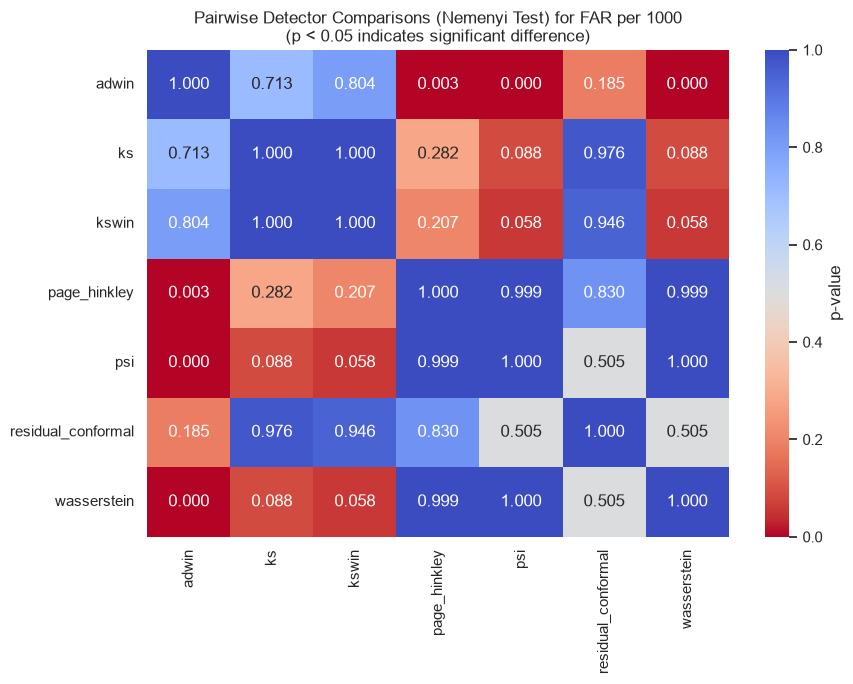

In [15]:
far_per_1000_results_matrix = evaluate_detectors_statistically(df_pivot_far_per_1000, metric_name="FAR per 1000")

### Level 2. Synthetic drift


=== Statistical Analysis for Metric: F1-Score ===
Friedreg/Chi-square Statistic: 66.5475
p-value: 2.0828e-12
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                           adwin        ks     kswin  page_hinkley       psi  \
adwin               1.000000e+00  0.074291  0.000329      0.034521  0.635976   
ks                  7.429105e-02  1.000000  0.742999      0.999970  0.917132   
kswin               3.285297e-04  0.742999  1.000000      0.880165  0.114352   
page_hinkley        3.452071e-02  0.999970  0.880165      1.000000  0.800433   
psi                 6.359760e-01  0.917132  0.114352      0.800433  1.000000   
residual_conformal  2.335721e-11  0.000329  0.074291      0.001039  0.000001   
wasserstein         9.171323e-01  0.635976  0.025298      0.455161  0.998341   

                    residual_conformal   wasserstein  
adwin                     2.335721e-11  9.171

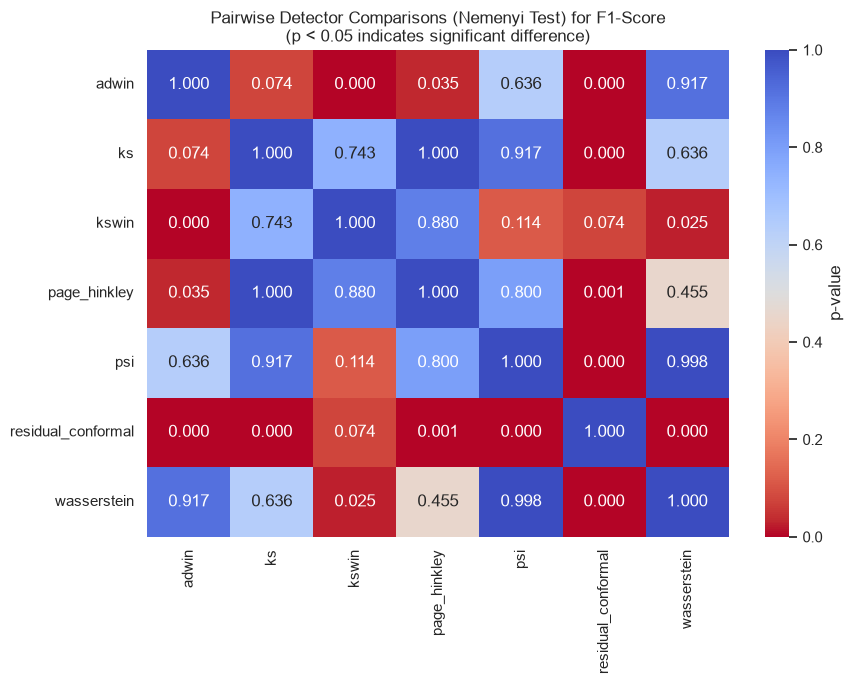

In [16]:
f1_results_matrix_synthetic_data = evaluate_detectors_statistically(df_pivot_f1_synthetic_data, metric_name="F1-Score")


=== Statistical Analysis for Metric: Detection Delay ===
Friedreg/Chi-square Statistic: 16.9964
p-value: 9.2966e-03
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                       adwin        ks     kswin  page_hinkley       psi  \
adwin               1.000000  0.383365  0.999459      0.999949  0.096148   
ks                  0.383365  1.000000  0.163298      0.577610  0.994704   
kswin               0.999459  0.163298  1.000000      0.990645  0.027494   
page_hinkley        0.999949  0.577610  0.990645      1.000000  0.191943   
psi                 0.096148  0.994704  0.027494      0.191943  1.000000   
residual_conformal  0.990645  0.844041  0.905096      0.999459  0.429896   
wasserstein         0.527684  0.999991  0.259158      0.722370  0.975835   

                    residual_conformal  wasserstein  
adwin                         0.990645     0.527684  
ks               

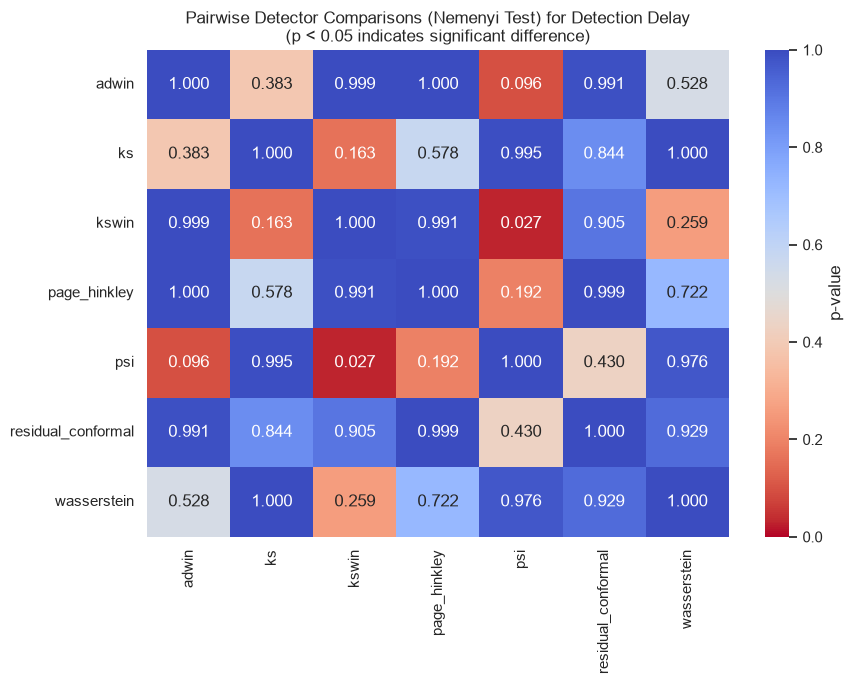

In [17]:
detection_delay_results_matrix_synthetic_data = evaluate_detectors_statistically(df_pivot_detection_delay_synthetic_data, metric_name="Detection Delay")

### Level 3. Real data drift

In [18]:
f1_results_matrix_real_data = evaluate_detectors_statistically(df_pivot_f1_real_data, metric_name="F1-Score")


=== Statistical Analysis for Metric: F1-Score ===
Friedreg/Chi-square Statistic: 8.9589
p-value: 1.7590e-01
Conclusion: No sufficient evidence to reject the null hypothesis (no significant differences found).


In [19]:
detection_delay_results_matrix_real_data = evaluate_detectors_statistically(df_pivot_detection_delay_real_data, metric_name="Detection Delay")


=== Statistical Analysis for Metric: Detection Delay ===
Friedreg/Chi-square Statistic: 6.0000
p-value: 4.2319e-01
Conclusion: No sufficient evidence to reject the null hypothesis (no significant differences found).
